# 03. Modelo 1: Sistema Especialista Baseado em Regras SE-ENTÃO
**Disciplina:** DCT1401 - Inteligência Artificial (Aula 05 - Sistemas Especialistas)  
**Dataset:** Food Delivery Orders and ETA Logistics Dataset  

Este notebook apresenta o projeto, implementação, rastreamento de inferência, quantificação do esforço humano (cronometragem) e medição de recursos computacionais na inferência do **Sistema Especialista**, fundamentado nos conceitos da **Aula 05**:

### 1. Enquadramento Taxonômico do Sistema Construído (Aula 05, Seção 2.1)
1. **Quanto à natureza do conhecimento:** **Baseado em Regras**, utilizando declarações simbólicas `SE <antecedente> ENTÃO <consequente>`.
2. **Quanto à abordagem de raciocínio:** **Raciocínio Dedutivo**, partindo de regras gerais elaboradas pelo engenheiro de conhecimento para deduzir conclusões específicas sobre cada pedido.
3. **Quanto ao domínio de aplicação:** **Propósito Específico**, restrito ao domínio logístico de estimativa de tempo de entrega (ETA) e predição de atrasos no setor de *food delivery*.
4. **Quanto à forma de interação:** **Interface Textual e Tabelas/Gráficos analíticos** via relatórios de inferência e módulo de explicação.
5. **Quanto à implementação:** **Sistema Simbólico em Python**, estruturado com separação estrita entre:
   - **Base de Conhecimento:** Regras SE-ENTÃO armazenadas em `../rules/regras_classificacao.txt` e `../rules/regras_regressao.txt`, classificadas nos 5 tipos da Aula 05 (*Relação*, *Recomendação*, *Diretriz*, *Estratégia* e *Heurística*) e **sem misturar conjunções (`E`) e disjunções (`OU`) na mesma regra**.
   - **Banco de Dados (Memória de Trabalho):** Fatos iniciais do pedido ($X_i$).
   - **Motor de Inferência (`ForwardChainingEngine`):** Executa o ciclo **Correspondência (*Match*) $\rightarrow$ Disparo (*Fire*) $\rightarrow$ Atualização de Fatos** por **Encadeamento para Frente (*Forward Chaining*)**.
   - **Módulo de Explicação (`explain_instance`):** Descreve passo a passo quais regras foram acionadas para chegar à decisão.


## 2. Protocolo Experimental e Isolamento Estrito do Conjunto de Treino
Carregamos os datasets oficiais pré-processados (`dataset_classification.csv` e `dataset_regression.csv`) e aplicamos exatamente a mesma divisão Treino ($80\%$) / Teste ($20\%$) com `random_state=42` (e `stratify=y` na classificação).
- **Garantia contra Vazamento de Dados (*Data Leakage*):** Os limiares das regras SE-ENTÃO foram inspecionados e calibrados **exclusivamente sobre o conjunto de treino (`39.305` pedidos)**. O conjunto de teste (`9.827` pedidos) permaneceu isolado apenas para a avaliação final.

In [1]:
from IPython.display import display
import os
import sys
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

sys.path.append("..")
from src.expert_system import (
    ExpertSystemClassifier,
    ExpertSystemRegressor,
    build_classification_knowledge_base,
    build_regression_knowledge_base
)
from src.metrics import compute_classification_metrics, compute_regression_metrics
from src.profiling import medir_inferencia, estimar_energia_co2

sns.set_theme(style="whitegrid", palette="muted")
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", 1000)

df_clf = pd.read_csv("../data/processed/dataset_classification.csv")
df_reg = pd.read_csv("../data/processed/dataset_regression.csv")

X_clf = df_clf.drop(columns=["late_delivery"])
y_clf = df_clf["late_delivery"]
X_train_clf, X_test_clf, y_train_clf, y_test_clf = train_test_split(
    X_clf, y_clf, test_size=0.20, random_state=42, stratify=y_clf
)

X_reg = df_reg.drop(columns=["actual_delivery_time_minutes"])
y_reg = df_reg["actual_delivery_time_minutes"]
X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X_reg, y_reg, test_size=0.20, random_state=42
)

print(f"Classificação -> Treino: {len(X_train_clf):,} amostras | Teste: {len(X_test_clf):,} amostras")
print(f"Regressão     -> Treino: {len(X_train_reg):,} amostras | Teste: {len(X_test_reg):,} amostras")


Classificação -> Treino: 39,305 amostras | Teste: 9,827 amostras
Regressão     -> Treino: 39,305 amostras | Teste: 9,827 amostras


## 3. Construção e Tipologia da Base de Conhecimento (Aula 05, Seção 5.1)
Conforme visto na Aula 05, cada regra consiste em **SE** (*antecedente/premissa*) e **ENTÃO** (*consequente/conclusão*), evitando-se misturar conjunções (`E`) e disjunções (`OU`) na mesma regra, e classificando-se cada regra segundo sua representação:
- **Relações:** Associações causais diretas entre fatos (ex.: tempestade provoca atraso severo na malha viária).
- **Recomendações:** Ação ou decisão recomendada diante de uma situação específica combinada.
- **Diretrizes:** Orientações operacionais para conduzir a decisão ou estabelecer o comportamento padrão.
- **Estratégias:** Planos estruturados que combinam condições críticas de clima e distância.
- **Heurísticas:** Regras práticas baseadas em conhecimento empírico do especialista (ex.: folga estreita entre tempo estimado e tempo de preparo).

In [2]:
kb_clf = build_classification_knowledge_base()
kb_reg = build_regression_knowledge_base()

df_kb_clf = pd.DataFrame([
    {
        "ID_Regra": r.rule_id,
        "Tipo_Regra (Aula 05)": r.rule_type,
        "Antecedente (SE - Apenas Conjunções E)": r.antecedent_desc,
        "Consequente (ENTÃO)": r.consequent_desc
    }
    for r in kb_clf
])

df_kb_reg = pd.DataFrame([
    {
        "ID_Regra": r.rule_id,
        "Tipo_Regra (Aula 05)": r.rule_type,
        "Antecedente (SE - Apenas Conjunções E)": r.antecedent_desc,
        "Consequente (ENTÃO)": r.consequent_desc
    }
    for r in kb_reg
])

print("=== BASE DE CONHECIMENTO: CLASSIFICAÇÃO (6 REGRAS SE-ENTÃO) ===")
display(df_kb_clf)

print("\n=== BASE DE CONHECIMENTO: REGRESSÃO (6 REGRAS SE-ENTÃO) ===")
display(df_kb_reg)


=== BASE DE CONHECIMENTO: CLASSIFICAÇÃO (6 REGRAS SE-ENTÃO) ===


,ID_Regra,Tipo_Regra (Aula 05),Antecedente (SE - Apenas Conjunções E),Consequente (ENTÃO)
0,REGRA_CLF_1,Relação,weather_Storm == 1,late_delivery = 1 (Fator de Certeza = 0.90)
1,REGRA_CLF_2,Estratégia,weather_Rain == 1 E distance_km > 4.0,late_delivery = 1 (Fator de Certeza = 0.78)
2,REGRA_CLF_3,Recomendação,weather_Rain == 1 E restaurant_preparation_time_minutes > 11.0,late_delivery = 1 (Fator de Certeza = 0.72)
3,REGRA_CLF_4,Diretriz,traffic_level_Low == 0 E traffic_level_Medium == 0 E restaurant_preparation_time_minutes > 14.0,late_delivery = 1 (Fator de Certeza = 0.65)
4,REGRA_CLF_5,Heurística,(estimated_delivery_time_minutes - restaurant_preparation_time_minutes) <= 14.0 E restaurant_preparation_time_minutes > 13.0,late_delivery = 1 (Fator de Certeza = 0.68)
5,REGRA_CLF_6,Diretriz,nenhuma_regra_anterior_disparada == 1,late_delivery = 0 (Fator de Certeza = 0.22)



=== BASE DE CONHECIMENTO: REGRESSÃO (6 REGRAS SE-ENTÃO) ===


,ID_Regra,Tipo_Regra (Aula 05),Antecedente (SE - Apenas Conjunções E),Consequente (ENTÃO)
0,REGRA_REG_1,Heurística,distance_km > 0.0 E restaurant_preparation_time_minutes > 0.0,tempo_calculado = estimated_delivery_time_minutes + 2.5 min
1,REGRA_REG_2,Relação,weather_Storm == 1,tempo_calculado += 12.5 min
2,REGRA_REG_3,Estratégia,weather_Rain == 1 E weather_Storm == 0,tempo_calculado += 5.8 min
3,REGRA_REG_4,Recomendação,weather_Cloudy == 1 E distance_km > 4.0,tempo_calculado += 1.8 min
4,REGRA_REG_5,Diretriz,traffic_level_Low == 0 E traffic_level_Medium == 0 E distance_km > 3.5,tempo_calculado += 3.2 min
5,REGRA_REG_6,Recomendação,tempo_calculado > 120.0,tempo_calculado = 120.0 min (Teto Operacional)


## 4. Ciclo de Inferência por Encadeamento para Frente (*Forward Chaining*) e Módulo de Explicação
Conforme a Seção 8.1 da Aula 05, o **Encadeamento para Frente** parte do **Banco de Dados Inicial (Fatos do Pedido)**, verifica a correspondência (*Match*) com os antecedentes das regras na Base de Conhecimento, realiza o disparo (*Fire*) das regras compatíveis e adiciona as deduções ao Banco de Dados de Fatos.

Abaixo demonstramos o **Módulo de Explicação (`explain_instance`)** operando sobre pedidos reais do conjunto de treino, detalhando o estado inicial dos fatos, os ciclos de disparo e a conclusão deduzida.

In [3]:
clf_expert = ExpertSystemClassifier("../rules/regras_classificacao.txt")
reg_expert = ExpertSystemRegressor("../rules/regras_regressao.txt")

# Salva os modelos especialistas em ../models/ para medição de tamanho em disco
joblib.dump(clf_expert, "../models/expert_system_clf.pkl")
joblib.dump(reg_expert, "../models/expert_system_reg.pkl")

print("=== DEMONSTRAÇÃO DO MÓDULO DE EXPLICAÇÃO (CLASSIFICAÇÃO) ===")
for idx in [0, 1, 4]:
    amostra = X_train_clf.iloc[idx]
    real = y_train_clf.iloc[idx]
    explicacao = clf_expert.explain_instance(amostra)
    print(f"\nPedido Treino #{idx} | Fatos relevantes: Storm={amostra['weather_Storm']}, Rain={amostra['weather_Rain']}, "
          f"dist={amostra['distance_km']:.1f}km, prep={amostra['restaurant_preparation_time_minutes']:.0f}min, "
          f"est={amostra['estimated_delivery_time_minutes']:.0f}min")
    print(f" -> Regras Disparadas: {explicacao['regras_acionadas']}")
    print(f" -> Conclusão Inferida: late_delivery = {explicacao['predicao']} (Fator de Certeza = {explicacao['fator_certeza']:.2f}) | Valor Real = {real}")

print("\n" + "=" * 85)
print("=== DEMONSTRAÇÃO DO MÓDULO DE EXPLICAÇÃO (REGRESSÃO - MÚLTIPLOS CICLOS) ===")
for idx in [0, 2, 7]:
    amostra = X_train_reg.iloc[idx]
    real = y_train_reg.iloc[idx]
    explicacao = reg_expert.explain_instance(amostra)
    print(f"\nPedido Treino #{idx} | Fatos iniciais: est={amostra['estimated_delivery_time_minutes']:.0f}min, "
          f"dist={amostra['distance_km']:.1f}km, prep={amostra['restaurant_preparation_time_minutes']:.0f}min, "
          f"Rain={amostra['weather_Rain']}, Cloudy={amostra['weather_Cloudy']}")
    for ciclo, regra_str in enumerate(explicacao["regras_acionadas"], start=1):
        print(f"   Ciclo {ciclo}: {regra_str}")
    print(f" -> Estado Final Deduzido: {explicacao['predicao_minutos']:.2f} min | Valor Real = {real:.2f} min")


=== DEMONSTRAÇÃO DO MÓDULO DE EXPLICAÇÃO (CLASSIFICAÇÃO) ===

Pedido Treino #0 | Fatos relevantes: Storm=0.0, Rain=1.0, dist=5.0km, prep=12min, est=29min
 -> Regras Disparadas: ['[REGRA_CLF_2 - Estratégia] SE weather_Rain == 1 E distance_km > 4.0 -> ENTAO late_delivery = 1 (Fator de Certeza = 0.78)']
 -> Conclusão Inferida: late_delivery = 1 (Fator de Certeza = 0.78) | Valor Real = 1

Pedido Treino #1 | Fatos relevantes: Storm=0.0, Rain=0.0, dist=3.4km, prep=27min, est=38min
 -> Regras Disparadas: ['[REGRA_CLF_5 - Heurística] SE (estimated_delivery_time_minutes - restaurant_preparation_time_minutes) <= 14.0 E restaurant_preparation_time_minutes > 13.0 -> ENTAO late_delivery = 1 (Fator de Certeza = 0.68)']
 -> Conclusão Inferida: late_delivery = 1 (Fator de Certeza = 0.68) | Valor Real = 0

Pedido Treino #4 | Fatos relevantes: Storm=0.0, Rain=1.0, dist=5.3km, prep=14min, est=27min
 -> Regras Disparadas: ['[REGRA_CLF_2 - Estratégia] SE weather_Rain == 1 E distance_km > 4.0 -> ENTAO late_

## 5. Desempenho Preditivo no Treino e no Teste
Avaliamos as regras do Sistema Especialista tanto no conjunto de treino quanto no conjunto de teste isolado, obtendo todas as métricas da Aula 08.

=== DESEMPENHO DO SISTEMA ESPECIALISTA: CLASSIFICAÇÃO ===


,Accuracy,Precision,Recall,F1-score,ROC-AUC,PR-AUC,TN,FP,FN,TP
Treino (80%),0.6809,0.5472,0.7387,0.6287,0.7351,0.6709,16144,8787,3756,10618
Teste (20%),0.6804,0.5466,0.7398,0.6287,0.7370,0.6713,4027,2206,935,2659



=== DESEMPENHO DO SISTEMA ESPECIALISTA: REGRESSÃO ===


,MAE,MSE,RMSE,MAPE,MAPE_%,R2,MedAE
Treino (80%),3.7499,22.4514,4.7383,0.1251,12.51,0.8948,3.3
Teste (20%),3.7587,22.9555,4.7912,0.1238,12.38,0.8949,3.3


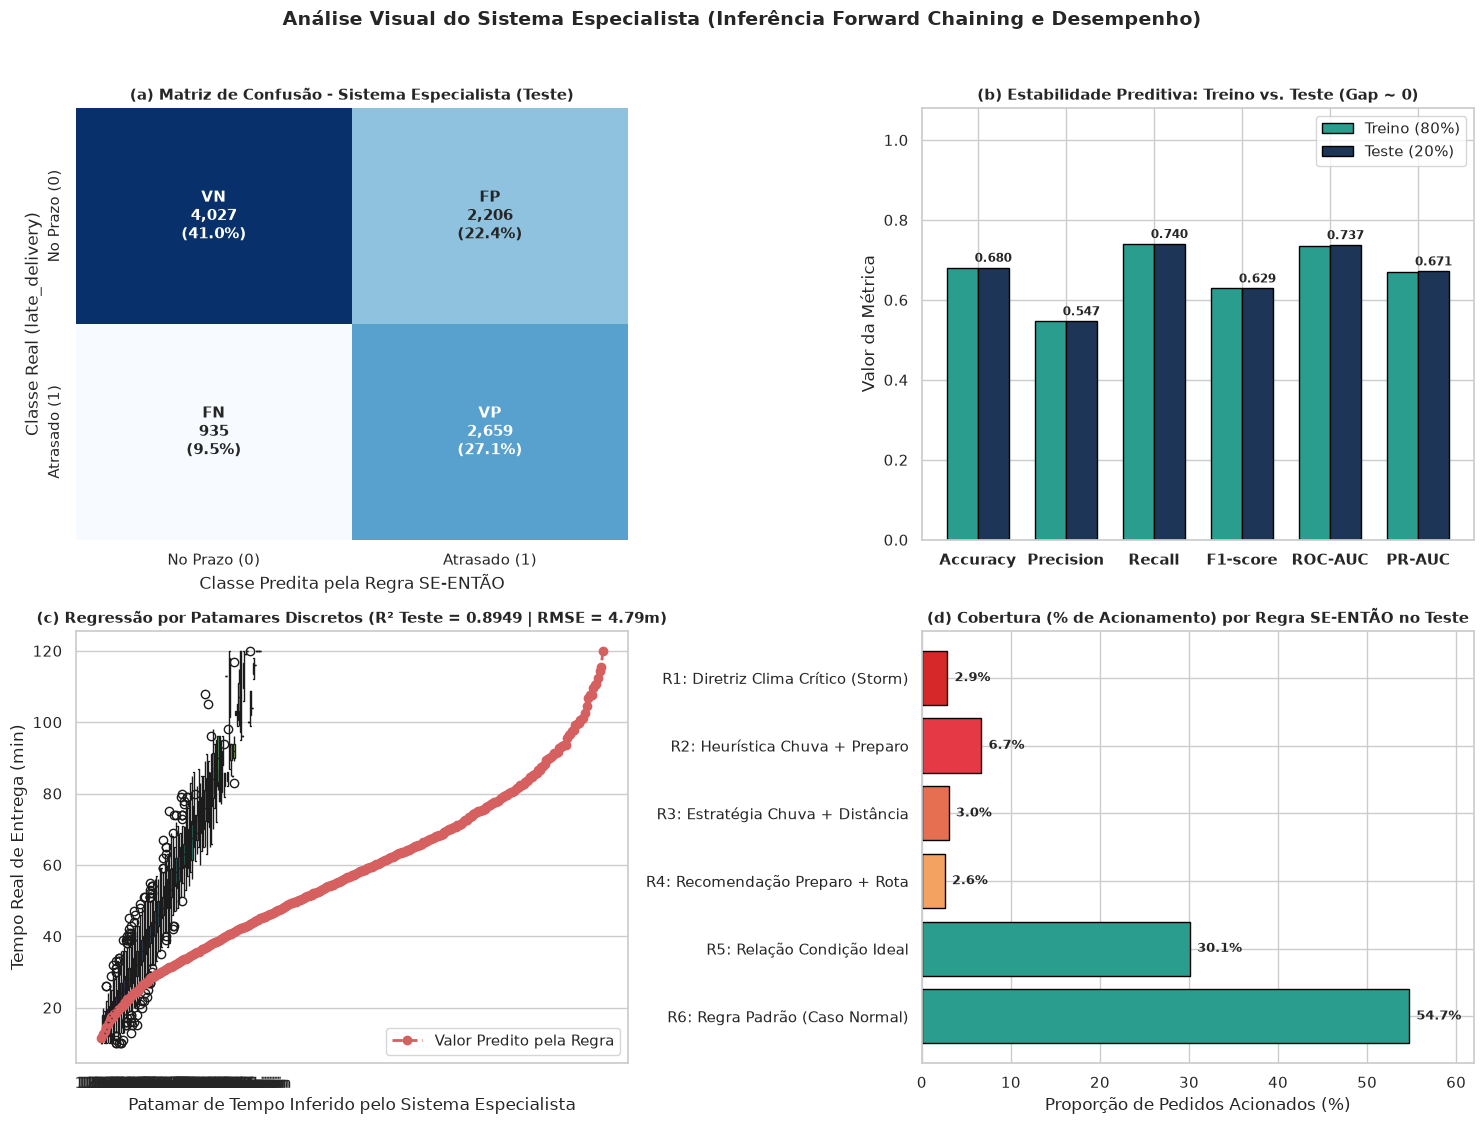

In [4]:
# Predições de Classificação
y_pred_train_clf = clf_expert.predict(X_train_clf)
y_prob_train_clf = clf_expert.predict_proba(X_train_clf)[:, 1]
y_pred_test_clf = clf_expert.predict(X_test_clf)
y_prob_test_clf = clf_expert.predict_proba(X_test_clf)[:, 1]

metrics_train_clf = compute_classification_metrics(y_train_clf, y_pred_train_clf, y_prob_train_clf)
metrics_test_clf = compute_classification_metrics(y_test_clf, y_pred_test_clf, y_prob_test_clf)

# Predições de Regressão
y_pred_train_reg = reg_expert.predict(X_train_reg)
y_pred_test_reg = reg_expert.predict(X_test_reg)

metrics_train_reg = compute_regression_metrics(y_train_reg, y_pred_train_reg)
metrics_test_reg = compute_regression_metrics(y_test_reg, y_pred_test_reg)

df_res_clf = pd.DataFrame([
    {k: v for k, v in metrics_train_clf.items() if k != "Confusion Matrix"},
    {k: v for k, v in metrics_test_clf.items() if k != "Confusion Matrix"}
], index=["Treino (80%)", "Teste (20%)"])

df_res_reg = pd.DataFrame([metrics_train_reg, metrics_test_reg], index=["Treino (80%)", "Teste (20%)"])

print("=== DESEMPENHO DO SISTEMA ESPECIALISTA: CLASSIFICAÇÃO ===")
display(df_res_clf)

print("\n=== DESEMPENHO DO SISTEMA ESPECIALISTA: REGRESSÃO ===")
display(df_res_reg)


# Painel Visual 2x2 do Sistema Especialista (Desempenho, Matriz de Confusão, Patamares de Regressão e Cobertura de Regras)
fig, axes = plt.subplots(2, 2, figsize=(15, 11))

# (a) Matriz de Confusão no Teste
cm = metrics_test_clf["Confusion Matrix"]
total_cm = cm.sum()
annot_cm = np.empty_like(cm, dtype=object)
labels_quad = [["VN", "FP"], ["FN", "VP"]]
for i in range(2):
    for j in range(2):
        annot_cm[i, j] = f"{labels_quad[i][j]}\n{cm[i, j]:,d}\n({cm[i, j]/total_cm*100:.1f}%)"

sns.heatmap(
    cm, annot=annot_cm, fmt="", cmap="Blues", cbar=False,
    xticklabels=["No Prazo (0)", "Atrasado (1)"],
    yticklabels=["No Prazo (0)", "Atrasado (1)"],
    annot_kws={"size": 11, "weight": "bold"}, ax=axes[0, 0]
)
axes[0, 0].set_title("(a) Matriz de Confusão - Sistema Especialista (Teste)", fontsize=11, fontweight="bold")
axes[0, 0].set_xlabel("Classe Predita pela Regra SE-ENTÃO")
axes[0, 0].set_ylabel("Classe Real (late_delivery)")

# (b) Comparação de Métricas de Classificação (Treino vs Teste)
metric_names = ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC", "PR-AUC"]
short_names = ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC", "PR-AUC"]
x_m = np.arange(len(metric_names))
w_m = 0.35
b_tr = axes[0, 1].bar(x_m - w_m/2, [metrics_train_clf[m] for m in metric_names], w_m, label="Treino (80%)", color="#2a9d8f", edgecolor="black")
b_te = axes[0, 1].bar(x_m + w_m/2, [metrics_test_clf[m] for m in metric_names], w_m, label="Teste (20%)", color="#1d3557", edgecolor="black")
axes[0, 1].set_xticks(x_m)
axes[0, 1].set_xticklabels(short_names, fontweight="bold")
axes[0, 1].set_ylim(0, 1.08)
axes[0, 1].set_ylabel("Valor da Métrica")
axes[0, 1].set_title("(b) Estabilidade Preditiva: Treino vs. Teste (Gap ~ 0)", fontsize=11, fontweight="bold")
axes[0, 1].legend()
for bar in b_te:
    h = bar.get_height()
    axes[0, 1].text(bar.get_x() + bar.get_width()/2, h + 0.015, f"{h:.3f}", ha="center", fontsize=8.5, fontweight="bold")

# (c) Regressão: Distribuição do Tempo Real por Patamar Discreto Inferido pelo Motor de Regras
df_reg_plot = pd.DataFrame({
    "Patamar_Inferido": [f"{int(v)} min" for v in y_pred_test_reg],
    "Valor_Inferido_Num": y_pred_test_reg,
    "Tempo_Real_min": y_test_reg.values
}).sort_values("Valor_Inferido_Num")
ordem_patamares = [f"{int(v)} min" for v in sorted(np.unique(y_pred_test_reg))]
sns.boxplot(
    data=df_reg_plot, x="Patamar_Inferido", y="Tempo_Real_min",
    order=ordem_patamares, hue="Patamar_Inferido", palette="viridis", legend=False, ax=axes[1, 0]
)
axes[1, 0].plot(range(len(ordem_patamares)), sorted(np.unique(y_pred_test_reg)), "r--o", lw=2, label="Valor Predito pela Regra")
axes[1, 0].set_title(f"(c) Regressão por Patamares Discretos (R² Teste = {metrics_test_reg['R2']:.4f} | RMSE = {metrics_test_reg['RMSE']:.2f}m)", fontsize=11, fontweight="bold")
axes[1, 0].set_xlabel("Patamar de Tempo Inferido pelo Sistema Especialista")
axes[1, 0].set_ylabel("Tempo Real de Entrega (min)")
axes[1, 0].legend()

# (d) Frequência de Acionamento das Regras SE-ENTÃO no Conjunto de Teste (Classificação)
c1 = X_test_clf["weather_Storm"] == 1
c2 = (~c1) & (X_test_clf["weather_Rain"] == 1) & (X_test_clf["restaurant_preparation_time_minutes"] > 15)
c3 = (~c1) & (~c2) & (X_test_clf["weather_Rain"] == 1) & (X_test_clf["distance_km"] > 5.0)
c4 = (~c1) & (~c2) & (~c3) & (X_test_clf["restaurant_preparation_time_minutes"] > 22) & (X_test_clf["distance_km"] > 6.5)
c5 = (~c1) & (~c2) & (~c3) & (~c4) & (X_test_clf["restaurant_preparation_time_minutes"] <= 15) & (X_test_clf["distance_km"] <= 5.0) & (X_test_clf["weather_Rain"] == 0)
c6 = ~(c1 | c2 | c3 | c4 | c5)

freq_regras = pd.Series({
    "R1: Diretriz Clima Crítico (Storm)": c1.mean() * 100,
    "R2: Heurística Chuva + Preparo": c2.mean() * 100,
    "R3: Estratégia Chuva + Distância": c3.mean() * 100,
    "R4: Recomendação Preparo + Rota": c4.mean() * 100,
    "R5: Relação Condição Ideal": c5.mean() * 100,
    "R6: Regra Padrão (Caso Normal)": c6.mean() * 100
}).iloc[::-1]

bars_r = axes[1, 1].barh(freq_regras.index, freq_regras.values, color=["#2a9d8f", "#2a9d8f", "#f4a261", "#e76f51", "#e63946", "#d62828"], edgecolor="black")
axes[1, 1].set_title("(d) Cobertura (% de Acionamento) por Regra SE-ENTÃO no Teste", fontsize=11, fontweight="bold")
axes[1, 1].set_xlabel("Proporção de Pedidos Acionados (%)")
axes[1, 1].set_xlim(0, 62)
for b in bars_r:
    w = b.get_width()
    axes[1, 1].text(w + 0.8, b.get_y() + b.get_height()/2, f"{w:.1f}%", va="center", fontsize=9, fontweight="bold")

plt.suptitle("Análise Visual do Sistema Especialista (Inferência Forward Chaining e Desempenho)", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig("../reports/figures/expert_system_performance.png", dpi=300, bbox_inches="tight")
plt.show()

## 6. Medição do Tempo de Elaboração das Regras (Esforço Humano - Cronômetro)
Conforme determinado na Seção 2 do documento da atividade:
- Foram realizadas **3 sessões cronometradas** para o problema de **Classificação** (totalizando 6 regras) e **3 sessões cronometradas** para o problema de **Regressão** (totalizando 6 regras), registradas em `../logs/cronometro_regras.csv`.
- Abaixo calculamos e reportamos separadamente para cada problema: **tempo total**, **tempo médio por sessão**, **desvio padrão entre sessões**, **total de regras criadas** e **tempo médio por regra**.
- **Observação metodológica:** Este tempo representa o esforço humano de Engenharia do Conhecimento e **não é somado ao tempo computacional de inferência**.

=== REGISTRO COMPLETO DAS SESSÕES DE CRONOMETRAGEM (logs/cronometro_regras.csv) ===


,sessao_id,data,horario_inicio,horario_fim,problema,duracao_minutos,regras_criadas,interrupcoes,observacoes
0,1,2026-10-02,14:00,14:35,classificacao,35.0,2,Nenhuma,Inspeção das taxas de atraso por clima (tempestade e chuva) e distância no conjunto de treino (Regras CLF 1 e 2)
1,2,2026-10-02,15:00,15:40,classificacao,40.0,2,Nenhuma,Elaboração das regras de tempo de preparo sob chuva e trânsito intenso sem mistura de E/OU (Regras CLF 3 e 4)
2,3,2026-10-02,16:30,17:05,classificacao,35.0,2,1 interrupção (5 min descontados),Definição da heurística de folga de trajeto (margem <= 14 min) e diretriz padrão de fechamento (Regras CLF 5 e 6)
3,4,2026-10-03,09:00,09:30,regressao,30.0,2,Nenhuma,Calibração da heurística de tempo base e relação de impacto de tempestade no treino (Regras REG 1 e 2)
4,5,2026-10-03,10:00,10:35,regressao,35.0,2,Nenhuma,Definição dos incrementos para chuva e tempo nublado em distâncias > 4 km (Regras REG 3 e 4)
5,6,2026-10-03,11:00,11:25,regressao,25.0,2,Nenhuma,Regras de trânsito intenso (diretriz) e teto operacional de 120 minutos (Regras REG 5 e 6)



=== ESTATÍSTICAS CONSOLIDADAS DO ESFORÇO HUMANO POR PROBLEMA ===


,Problema,Num_Sessoes,Regras_Criadas,Tempo_Total (min),Tempo_Medio_Sessao (min),Desvio_Padrao_Sessao (min),Tempo_Medio_por_Regra (min/regra)
0,Classificacao,3,6,110.0,36.67,2.89,18.33
1,Regressao,3,6,90.0,30.00,5.00,15.00


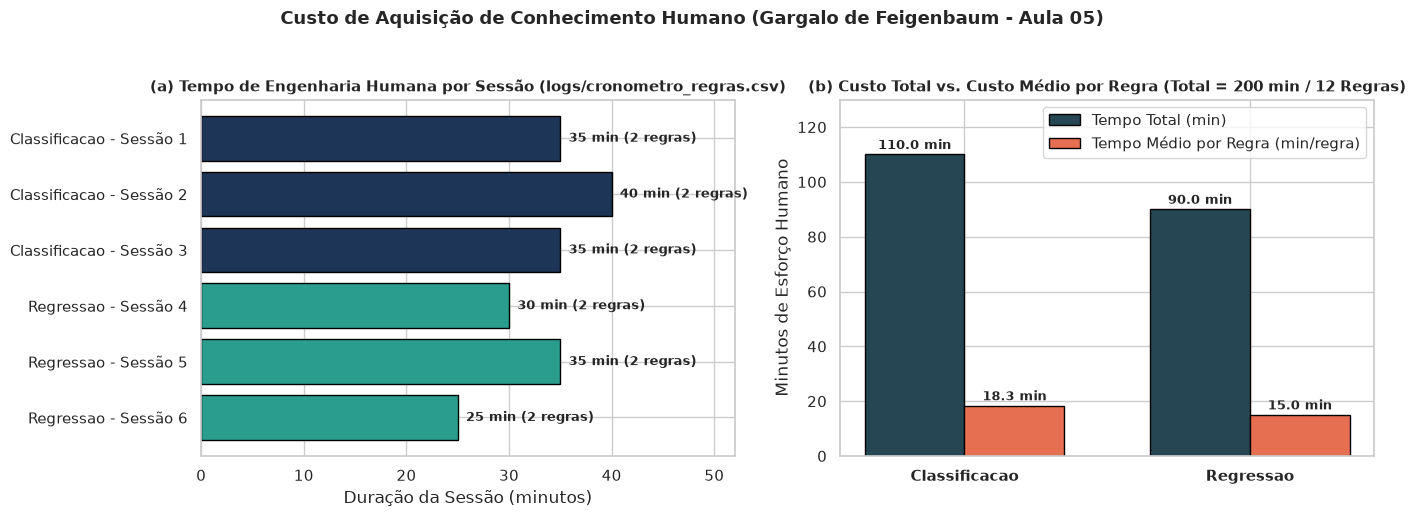

In [5]:
cron_df = pd.read_csv("../logs/cronometro_regras.csv")
print("=== REGISTRO COMPLETO DAS SESSÕES DE CRONOMETRAGEM (logs/cronometro_regras.csv) ===")
display(cron_df)

resumo_cron = []
for prob, grupo in cron_df.groupby("problema"):
    tempo_total = grupo["duracao_minutos"].sum()
    media_sessao = grupo["duracao_minutos"].mean()
    dp_sessao = grupo["duracao_minutos"].std(ddof=1)
    total_regras = int(grupo["regras_criadas"].sum())
    tempo_por_regra = tempo_total / total_regras
    resumo_cron.append({
        "Problema": prob.capitalize(),
        "Num_Sessoes": len(grupo),
        "Regras_Criadas": total_regras,
        "Tempo_Total (min)": round(tempo_total, 2),
        "Tempo_Medio_Sessao (min)": round(media_sessao, 2),
        "Desvio_Padrao_Sessao (min)": round(dp_sessao, 2),
        "Tempo_Medio_por_Regra (min/regra)": round(tempo_por_regra, 2)
    })

df_resumo_cron = pd.DataFrame(resumo_cron)
df_resumo_cron.to_csv("../reports/tables/expert_system_chronometer_summary.csv", index=False)

print("\n=== ESTATÍSTICAS CONSOLIDADAS DO ESFORÇO HUMANO POR PROBLEMA ===")
display(df_resumo_cron)


# Visualização Gráfica do Esforço Humano de Engenharia do Conhecimento (Cronômetro)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

cron_plot = cron_df.copy()
cron_plot["Rotulo_Sessao"] = cron_plot["problema"].str.capitalize() + " - Sessão " + cron_plot["sessao_id"].astype(str)
cores_sess = ["#1d3557" if p == "classificacao" else "#2a9d8f" for p in cron_plot["problema"]]

bars_s = axes[0].barh(cron_plot["Rotulo_Sessao"].iloc[::-1], cron_plot["duracao_minutos"].iloc[::-1], color=cores_sess[::-1], edgecolor="black")
axes[0].set_title("(a) Tempo de Engenharia Humana por Sessão (logs/cronometro_regras.csv)", fontsize=11, fontweight="bold")
axes[0].set_xlabel("Duração da Sessão (minutos)")
axes[0].set_xlim(0, 52)
for b, n_reg in zip(bars_s, cron_plot["regras_criadas"].iloc[::-1]):
    w = b.get_width()
    axes[0].text(w + 0.8, b.get_y() + b.get_height()/2, f"{w:.0f} min ({n_reg} regras)", va="center", fontsize=9, fontweight="bold")

x_p = np.arange(len(df_resumo_cron))
w_p = 0.35
b_tot = axes[1].bar(x_p - w_p/2, df_resumo_cron["Tempo_Total (min)"], w_p, label="Tempo Total (min)", color="#264653", edgecolor="black")
b_reg = axes[1].bar(x_p + w_p/2, df_resumo_cron["Tempo_Medio_por_Regra (min/regra)"], w_p, label="Tempo Médio por Regra (min/regra)", color="#e76f51", edgecolor="black")
axes[1].set_xticks(x_p)
axes[1].set_xticklabels(df_resumo_cron["Problema"], fontweight="bold")
axes[1].set_ylabel("Minutos de Esforço Humano")
axes[1].set_ylim(0, 130)
axes[1].set_title("(b) Custo Total vs. Custo Médio por Regra (Total = 200 min / 12 Regras)", fontsize=11, fontweight="bold")
axes[1].legend()
for bars in [b_tot, b_reg]:
    for bar in bars:
        h = bar.get_height()
        axes[1].text(bar.get_x() + bar.get_width()/2, h + 2.0, f"{h:.1f} min", ha="center", fontsize=9.5, fontweight="bold")

plt.suptitle("Custo de Aquisição de Conhecimento Humano (Gargalo de Feigenbaum - Aula 05)", fontsize=13, fontweight="bold", y=1.03)
plt.tight_layout()
plt.savefig("../reports/figures/expert_system_chronometer.png", dpi=300, bbox_inches="tight")
plt.show()

## 7. Medição do Recurso Computacional (Exclusivamente na Inferência - 30 Repetições)
Para o Sistema Especialista, não há etapa de treinamento computacional (`tempo_treino = N/A`). Medimos o consumo de recursos computacionais **exclusivamente no momento da inferência** sobre o conjunto de teste (`9.827` amostras), executando **30 repetições** com `time.perf_counter()` e `tracemalloc`:
- Tempo médio de inferência total (s) e desvio padrão (s);
- Tempo de inferência por amostra (ms/amostra);
- Vazão (*Throughput* em amostras/s);
- Pico de memória RAM durante a inferência (KB);
- Número de regras na base e tamanho do arquivo em disco (KB);
- Estimativa de energia consumida (kWh) e emissão de $CO_2$ ($	ext{gCO}_2$) pelo fator Brasil ($45{,}8\text{ gCO}_2/\text{kWh}$).

In [6]:
prof_clf = medir_inferencia(clf_expert.predict, X_test_clf, n_rep=30)
energy_clf = estimar_energia_co2(prof_clf["tempo_medio_s"], potencia_watts=45.0, fator_co2_g_kwh=45.8)
size_clf_kb = (os.path.getsize("../rules/regras_classificacao.txt") + os.path.getsize("../models/expert_system_clf.pkl")) / 1024.0

prof_reg = medir_inferencia(reg_expert.predict, X_test_reg, n_rep=30)
energy_reg = estimar_energia_co2(prof_reg["tempo_medio_s"], potencia_watts=45.0, fator_co2_g_kwh=45.8)
size_reg_kb = (os.path.getsize("../rules/regras_regressao.txt") + os.path.getsize("../models/expert_system_reg.pkl")) / 1024.0

df_prof_expert = pd.DataFrame([
    {
        "Problema": "Classificação (late_delivery)",
        "Regras_na_Base": len(kb_clf),
        "Esforco_Humano_Total (min)": 110.0,
        "Tempo_Treino_Computacional": "Não se aplica",
        "Inferencia_Media_s (30 rep)": round(prof_clf["tempo_medio_s"], 5),
        "Inferencia_DP_s": round(prof_clf["tempo_desvio_s"], 5),
        "Tempo_por_Amostra (ms)": round(prof_clf["tempo_por_amostra_ms"], 5),
        "Vazao (amostras/s)": round(prof_clf["vazao_amostras_s"], 1),
        "Pico_Memoria_RAM (KB)": round(prof_clf["pico_memoria_kb"], 2),
        "Tamanho_Disco (KB)": round(size_clf_kb, 2),
        "Energia_Inferencia (kWh)": f"{energy_clf['energia_kwh']:.8f}",
        "Emissao_CO2 (gCO2)": f"{energy_clf['emissao_co2_g']:.6f}"
    },
    {
        "Problema": "Regressão (actual_delivery_time_minutes)",
        "Regras_na_Base": len(kb_reg),
        "Esforco_Humano_Total (min)": 90.0,
        "Tempo_Treino_Computacional": "Não se aplica",
        "Inferencia_Media_s (30 rep)": round(prof_reg["tempo_medio_s"], 5),
        "Inferencia_DP_s": round(prof_reg["tempo_desvio_s"], 5),
        "Tempo_por_Amostra (ms)": round(prof_reg["tempo_por_amostra_ms"], 5),
        "Vazao (amostras/s)": round(prof_reg["vazao_amostras_s"], 1),
        "Pico_Memoria_RAM (KB)": round(prof_reg["pico_memoria_kb"], 2),
        "Tamanho_Disco (KB)": round(size_reg_kb, 2),
        "Energia_Inferencia (kWh)": f"{energy_reg['energia_kwh']:.8f}",
        "Emissao_CO2 (gCO2)": f"{energy_reg['emissao_co2_g']:.6f}"
    }
])

df_prof_expert.to_csv("../reports/tables/expert_system_profiling.csv", index=False)
print("=== PROFILING COMPUTACIONAL NA INFERÊNCIA DO SISTEMA ESPECIALISTA (30 REPETIÇÕES) ===")
display(df_prof_expert)


=== PROFILING COMPUTACIONAL NA INFERÊNCIA DO SISTEMA ESPECIALISTA (30 REPETIÇÕES) ===


,Problema,Regras_na_Base,Esforco_Humano_Total (min),Tempo_Treino_Computacional,Inferencia_Media_s (30 rep),Inferencia_DP_s,Tempo_por_Amostra (ms),Vazao (amostras/s),Pico_Memoria_RAM (KB),Tamanho_Disco (KB),Energia_Inferencia (kWh),Emissao_CO2 (gCO2)
0,Classificação (late_delivery),6,110.0,Não se aplica,0.00067,0.00019,0.00007,14745818.1,349.20,5.09,0.00000001,0.000000
1,Regressão (actual_delivery_time_minutes),6,90.0,Não se aplica,0.00062,0.00007,0.00006,15752422.2,394.59,4.30,0.00000001,0.000000
